# Experiment series and ParallelismProfiler

Tutorial CPU notebook for stage 09. It shows plan → runner → exact reference →
profile of a complete small grid → global recommendation → plots. All results are
read from saved records; the profile does not re-run the solver when a plot is
drawn.

In [1]:
from pathlib import Path
import json
import os
import tempfile

ROOT = Path.cwd()
if not (ROOT / "experiments").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

from QA_max_cut_lib import BenchmarkSpec, ExperimentRunner, ParallelismProfiler, tools

spec = tools.load_json("experiments/benchmark_small.json")
plan = tools.plan_experiments(spec)
print(plan.summary)
print(json.dumps(plan.counts, ensure_ascii=False, indent=2))
assert plan.counts["cases"] == 28
assert plan.counts["trials"] == 56


graphs=2 cases=28 trials=56 rejected=0 references=2
{
  "graph_instances": 2,
  "cases": 28,
  "raw_solver_configs": 28,
  "accepted_solver_configs": 28,
  "rejected_solver_configs": 0,
  "trials": 56,
  "reference_jobs": 2,
  "planned_top_level_runs": 58
}


## Small series

`benchmark_small.json` contains two graphs (8 and 10 vertices), four mean
configurations, eight cvar configurations and two SA configurations. The exact
maximum is computed separately.

In [2]:
run_spec = json.loads(Path("experiments/benchmark_small.json").read_text(encoding="utf-8"))
root = Path(tempfile.mkdtemp(prefix="qa_stage09_notebook_"))
run_spec["save"] = {
    "path": str(root),
    "filename": "small_comparison",
    "makedir": True,
    "savedir": True,
    "atts": ["trials", "references", "summary"],
    "save_original_data": [],
}
series = ExperimentRunner(run_spec).run()
print(series.summary)
print(json.dumps(series.analysis["by_solver"], ensure_ascii=False, indent=2)[:1600])
assert series.analysis["planned"] == 56
assert series.analysis["valid"] == 56
assert series.analysis["failed"] == 0
assert len(series.references) == 2


planned=56 valid=56 failed=0 skipped=0 success(valid)=0.6607142857142857 wall=1.060s
{
  "qaoa_mean": {
    "planned": 16,
    "valid": 16,
    "failed": 0,
    "skipped": 0,
    "cut": {
      "count": 16,
      "mean": 13.125,
      "median": 13.5,
      "min": 7.0,
      "max": 22.0,
      "stdev": 4.145278438577237
    },
    "gap": {
      "count": 16,
      "mean": 4.875,
      "median": 3.0,
      "min": 0.0,
      "max": 12.0,
      "stdev": 5.277309920783504
    },
    "success": 0.5
  },
  "qaoa_cvar": {
    "planned": 32,
    "valid": 32,
    "failed": 0,
    "skipped": 0,
    "cut": {
      "count": 32,
      "mean": 14.625,
      "median": 14.0,
      "min": 7.0,
      "max": 22.0,
      "stdev": 4.463110444377293
    },
    "gap": {
      "count": 32,
      "mean": 3.375,
      "median": 0.0,
      "min": 0.0,
      "max": 13.0,
      "stdev": 4.903915486300125
    },
    "success": 0.65625
  },
  "sa": {
    "planned": 8,
    "valid": 8,
    "failed": 0,
    "skipped": 0

## Exact reference and quality

ReferencePolicy stores the exact maximum in a separate record. `optimality_gap`
is computed as `C_star - C`; `ratio` does not replace that difference.

In [3]:
for ref in series.references:
    print(ref["kind"], ref["status"], ref["cut_value"], ref["proof"])
assert all(ref["proof"] == "exhaustive" for ref in series.references)

first = series.analysis["trials"][0]
print("first gap:", first["metrics"]["optimality_gap"])
print("q_range requires both extrema:", first["metrics"]["q_range_reason"])


exact_max_cut completed 14.0 exhaustive
exact_max_cut completed 22.0 exhaustive
first gap: 0.0
q_range requires both extrema: requires_both_exact_extrema


## Parallel profile

The profile uses the same spec, one selected seed and the full grid of all cases.
The numbers below are real measurements on this machine; they are not a universal
benchmark.

In [4]:
profile_cfg = json.loads(Path("tools/parallelism_sweep.json").read_text(encoding="utf-8"))
profile_cfg.pop("save", None)
profile = ParallelismProfiler(run_spec, profile_cfg).run()
print(profile.summary)
print("recommendation:", profile.analysis["recommendation"])
print("fit:", profile.analysis["fit_amdahl"])
assert profile.plan.points == 84
assert len(profile.measured_records) == 252
assert len(profile.warmup_records) == 84


seed=11 points=84 calls=336 recommended=1 wall=3.365s
recommendation: {'raw_argmin': 1, 'recommended_num_treads': 1, 'tolerance_rel': 0.03, 'search_complete': True, 'best_observed_complete': 1, 'reason': None}
fit: {'points': 3, 'n_values': [1, 2, 4], 'a': 0.24193674999999995, 'b': -0.021507000000000078, 't1': 0.22042974999999987, 'serial_fraction': 1.0975684997147621, 'parallel_fraction': -0.09756849971476211, 'serial_percent': 109.75684997147621, 'parallel_percent': -9.75684997147621, 'rmse': 0.0020100017276111666, 'relative_rmse': 0.008762339096177124, 'minimum_coverage': True, 'applicability': 'boundary_or_unphysical', 'boundary': True}


## Plot and standalone HTML

The profile is already saved in memory; the plot reads only records/analysis.

figure: C:\Users\Alexey\AppData\Local\Temp\qa_stage09_notebook_w2bcjdvd\figures\parallelism_parallelism.png


html: C:\Users\Alexey\AppData\Local\Temp\qa_stage09_notebook_w2bcjdvd\figures\parallelism_report.html


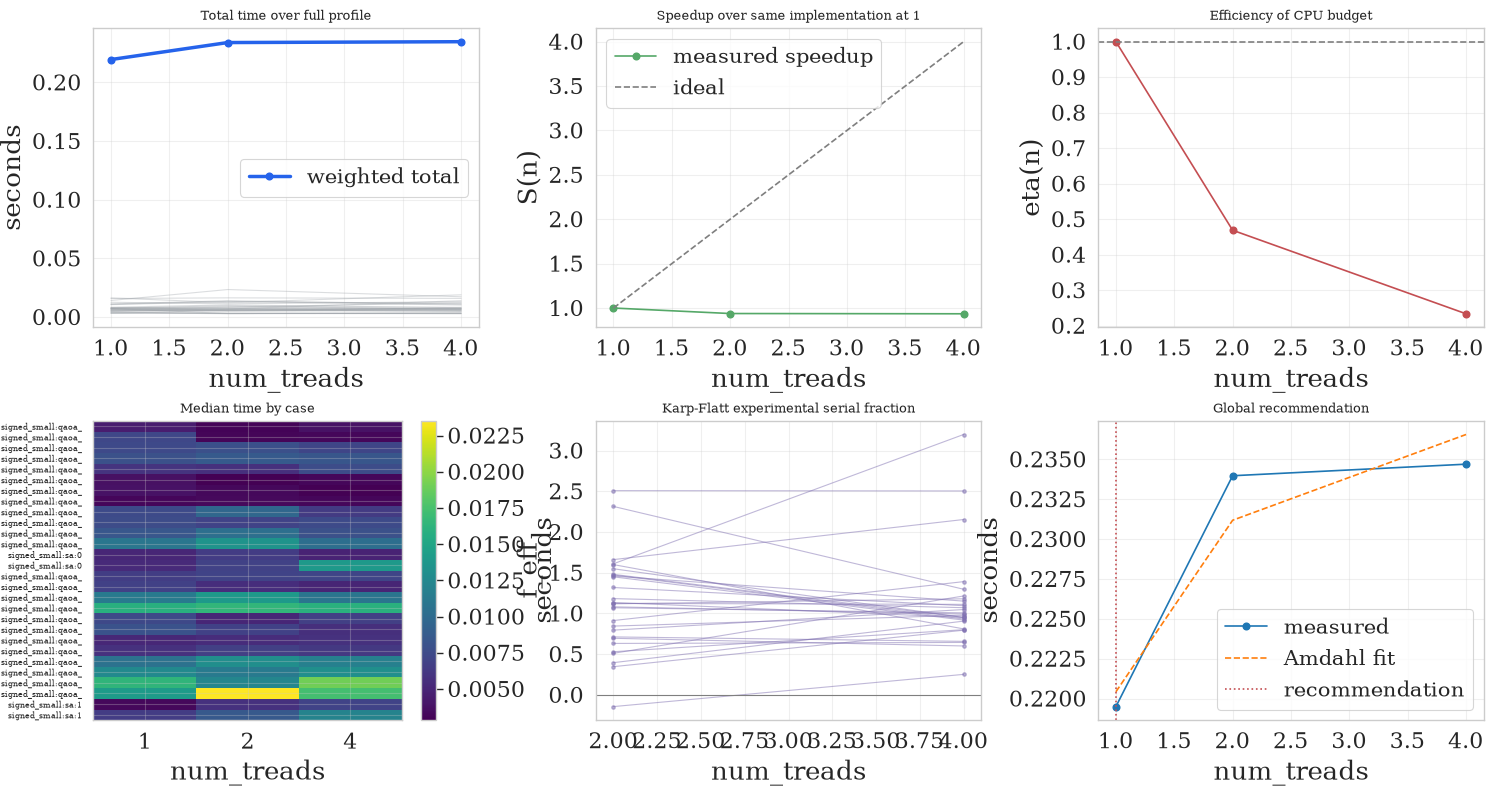

In [5]:
out = root / "figures"
fig = tools.plot_parallelism(profile, {
    "style": {"figsize": [15, 8]},
    "save": {"path": str(out), "filename": "parallelism", "format": "png", "DPI": 100, "makedir": True},
})
print("figure:", out / "parallelism_parallelism.png")
html_files = tools.parallelism_html(profile, {
    "style": {"figsize": [12, 7]},
    "save": {"path": str(out), "filename": "parallelism_report", "makedir": True},
})
print("html:", html_files.primary)


## The global recommendation is not a vote of local minima

Synthetic control D: A is good at n=4, B at n=1, but the overall minimum is at n=2.

In [6]:
curve = [
    {"n": 1, "total_seconds": 26.0, "complete": True},
    {"n": 2, "total_seconds": 24.0, "complete": True},
    {"n": 4, "total_seconds": 29.0, "complete": True},
]
rec = tools.recommend_total_curve(curve, tolerance_rel=0.03)
print(rec)
assert rec["raw_argmin"] == 2 and rec["recommended_num_treads"] == 2


{'raw_argmin': 2, 'recommended_num_treads': 2, 'tolerance_rel': 0.03, 'search_complete': False, 'best_observed_complete': 2, 'reason': None}


## Summary

- Full product: 28 cases, 56 scientific trials, 2 exact references.
- Profile: 84 case/candidate points, 84 warmup + 252 measured calls.
- The recommendation considers the whole set of cases and never reports failed/missing as zero.
- Plots and HTML use saved records and do not call the solver.
- The GPU profile does not run in this CPU notebook; the hardware part is noted
  separately in the report.